# **Árvores de Decisão: Investigando a Hipótese do Titanic**

## 1. Problema dos Algoritmos
Até agora, vimos os algoritmos **Máquinas de Vetores de Suporte (SVM)** e o **Naïve Bayes**. No entanto, uma crítica muito comum a esses métodos estatísticos e lineares é que eles funcionam quase como uma **"caixa-preta"**: não se pode explicar **como** o modelo chegou a uma determinada decisão final...

* **SVM:** Se tivermos dados com dezenas de características (alta dimensionalidade), é impossível para a mente humana visualizar ou desenhar o hiperplano que separa as classes. 

* **Naïve Bayes:** O algoritmo simplesmente diz que **uma determinada classe é a mais provável**, supondo que os dados seguem a mesma distribuição de frequência dos dados de treino e que as variáveis são independentes. 

Essas afirmações não ajudam muito quando precisamos justificar o **motivo** real da decisão. Imagine um médico precisando explicar um diagnóstico (como vimos no caso do AVC) ou um banco negando um empréstimo: não basta dizer *"foi o computador que decidiu"*, precisamos entender a regra lógica por trás da escolha!

## 2. Funcionamento da Árvore de Decisão
As **Árvores de Decisão** (*Decision Trees*) são métodos de **aprendizado supervisionado** simples, mas extremamente poderosos, que resolvem problemas de interpretação. Elas funcionam exatamente como um fluxograma de perguntas e respostas (ou como aquele clássico jogo de mesa *Cara a Cara*).

<div style="text-align: center; margin: 20px 0;">
    <img src="./img/cara-a-cara.png" alt="Criança com o Jogo Cara-a-cara." style="width: 33%; max-width: 500px; height: auto; border-radius: 6px; box-shadow: 0 4px 8px rgba(0,0,0,0.15);">
</div>

Veja abaixo uma **árvore de decisão** muito simples para decidir se um *e-mail* é **Spam** (*e-mail* contendo informações não solicitadas, indesejadas e enviadas de forma repetitiva e intrusiva) ou **Ham** (*e-mail* confiável/desejado):

<div style="text-align: center; margin: 20px 0;">
    <img src="./img/spam_ou_ham.jpg" alt="Exemplo de Árvore de Decisão: Spam ou Ham" style="width: 40%; max-width: 600px; height: auto; border-radius: 6px; box-shadow: 0 4px 8px rgba(0,0,0,0.15);">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        Exemplo de uma Árvore de Decisão simples para classificação de e-mails (<i>Spam ou Ham</i>).
    </p>
</div>

> **Esse modelo pode ser facilmente seguido no caso de se precisar de uma explicação!**  
> Qualquer pessoa consegue acompanhar o caminho das setas da **árvore de decisão** e entender exatamente por que o *e-mail* foi bloqueado ou liberado!

Para uma fundamentação teórica mais detalhada consulte o Anexo-A nesse mesmo material.

## 3. Aplicação: A Tragédia do Titanic  

Na noite de 14 de abril de 1912, o **RMS Titanic** — o maior e mais luxuoso navio de passageiros de sua época — colidiu com um iceberg em sua viagem inaugural pelo Oceano Atlântico. Considerado "inafundável", o transatlântico afundou na madrugada do dia seguinte, resultando em uma das maiores catástrofes marítimas em tempos de paz da história moderna.  

A tragédia não foi apenas um desastre de engenharia, mas um evento social impactante. O navio operava sob um rígido sistema de classes sociais e uma forte cultura eduardiana de códigos de conduta (como o protocolo "mulheres e crianças primeiro"). Diante da escassez de botes salva-vidas, que podiam abrigar apenas metade das pessoas a bordo, esses fatores sociais e demográficos tornaram-se determinantes entre a vida e a morte.  

Naquela viagem inaugural, o **Titanic** transportava *cerca* de 1.317 passageiros pagantes (além de *cerca* de 891 tripulantes). Para fins de ciência de dados e modelagem preditiva, o conjunto de dados padrão internacionalmente consolidado (frequentemente utilizado em plataformas como o Kaggle e repositórios acadêmicos) apresenta um total de 1.309 passageiros.

Vamos investigar um dos eventos históricos mais famosos do mundo: o naufrágio do **Titanic**. 

<div style="text-align: center; margin: 20px 0;">
    <img src="./img/rms-titanic-14047.png" alt="RMS Titanic" style="width: 40%; height: auto; border-radius: 6px;">
    <img src="./img/southhampton-london.png" alt="RMS Titanic" style="width: 40%; height: auto; border-radius: 6px;">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">  
        <b>RMS Titanic</b> partindo de Southampton para sua viagem inaugural, em 10/04/1912.
    </p>
</div>

O nosso objetivo é determinar se um passageiro teria sobrevivido ou não à tragédia baseando-se em apenas três características: **Idade (`age`)**, **Classe (`pclass`)** e **Sexo (`sex`)**. Será que a famosa regra *"mulheres e crianças primeiro"* realmente aconteceu na prática? A **árvore de decisão** vai nos dizer!

### 3.1 Explorando o Conjunto de Dados 
Trabalharemos com o conjunto de dados oficial do **Titanic** (disponível em https://hbiostat.org/data/), que inclui a lista de **1.309 passageiros** (sem dados de tripulantes) e uma coluna indicando a situação de sobrevivência do passageiro ou não. Cada linha no arquivo CSV tem o seguinte formato:

`"1","1","Allen, Miss. Elisabeth Walton","female","29","0","0","24160","211.3375","B5","S","2","","St Louis, MO"`

Ao todo são **14 atributos** (colunas) registrados:
<center>

|Atributo| Índice | Descrição |
|:------:|:------:|:----------|
| `pclass` | 0| Classe socioeconômica (`1` = 1ª, `2` = 2ª, `3` = 3ª classe) |
| `survived` | 1| Atributo **Alvo** (`0` = Não sobreviveu, `1` = Sobreviveu) |
| `name` | 2| Nome completo do passageiro |
| `sex` | 3| Sexo (`male` ou `female`) |
| `age` | 4| Idade em anos |
| `sibsp` | 5| Número de irmãos/cônjuges (em inglês: *siblings/spouses*) a bordo |
| `parch` | 6| Número de pais/filhos (em inglês: *parents/children*) a bordo. <br> Quantidade total de pais e/ou filhos que tinha viajado junto com o passageiro |
| `ticket` | 7| Número da passagem |
| `fare` | 8| Valor pago pela tarifa |
| `cabin` | 9| Número do quarto/cabine |
| `embarked` | 10| Porto de embarque (`C`, `Q` ou `S`) |
| `boat` | 11| Número do bote salva-vidas |
| `body` | 12| Número de identificação do corpo |
| `home.dest` | 13| Origem / Destino |

</center>

Vamos começar carregando o arquivo `titanic3.csv` diretamente em matrizes do `numpy` usando o módulo nativo `csv` do Python.

In [1]:
import csv
import numpy as np

# Abre o arquivo titanic3.csv 
with open('./dat/titanic3.csv', 'r', encoding='utf-8') as csvfile:
    leitor = csv.reader(csvfile, delimiter=',', quotechar='"')
    
    # A primeira linha (cabeçalho) contém os nomes das características (features)
    linha = next(leitor)                        # retorna lista contendo os dados da 'linha'
    caracteristicas = np.array(linha)           # converte lista 'linha' em vetor 
    
    # Carregando os dados (X) e a classe alvo (y)
    titanic_X, titanic_y = [], []
    registros = 0
    for linha in leitor:
        if len(linha) > 0 and linha[0] != '':   # ignora as linhas em branco no final do arquivo
            registros += 1
            titanic_X.append(linha)
            titanic_y.append(linha[1])          # segundo atributo "survived"
            
    titanic_X = np.array(titanic_X)             # converte lista 'titanic_X' em vetor
    titanic_y = np.array(titanic_y)             # converte lista 'titanic_Y' em vetor
    print("Registros lidos:", registros)

Registros lidos: 1309


In [2]:
# Imprimindo os nomes das características (features)
print("Colunas (características/features) do Conjunto de Dados:")
print(caracteristicas)
print("\nPrimeiro(a) Passageiro(a) (X):\n", titanic_X[0])
print("\nSobreviveu ao naufrágio?  (y): ", end='')
if titanic_y[0] == '1': 
    print("sim")
else: 
    print("não")

Colunas (características/features) do Conjunto de Dados:
['pclass' 'survived' 'name' 'sex' 'age' 'sibsp' 'parch' 'ticket' 'fare'
 'cabin' 'embarked' 'boat' 'body' 'home.dest']

Primeiro(a) Passageiro(a) (X):
 ['1' '1' 'Allen, Miss. Elisabeth Walton' 'female' '29' '0' '0' '24160'
 '211.3375' 'B5' 'S' '2' '' 'St Louis, MO']

Sobreviveu ao naufrágio?  (y): sim


## 4. Pré-processamento dos Dados 

O primeiro passo prático em qualquer projeto de *Machine Learning* é a escolha dos **atributos (colunas)** a serem usados pelo algoritmo. Esse processo é chamado de **Seleção de Características (*Features Selection*)**.

In [3]:
# Vamos escolher apenas três características: a Classe (índice 0), a Idade (índice 4) e o Sexo (índice 3)
titanic_X = titanic_X[:, [0, 4, 3]]
caracteristicas = caracteristicas[[0, 4, 3]]
print("Caracteristicas escolhidas:", caracteristicas)

Caracteristicas escolhidas: ['pclass' 'age' 'sex']


Se entregarmos dados ruins ou irrelevantes como entrada, o modelo não terá material de qualidade para aprender — no jargão da computação, chamamos isso de *"Garbage In, Garbage Out"* ("Entra Lixo, Sai Lixo"). Não importa se o algoritmo é o mais avançado do mundo, sem boas variáveis, o resultado será ruim!

<div style="background-color: #cfcff8; border-left: 5px solid; border-right: 5px solid #773014; padding: 15px; margin: 15px -25px; border-radius: 4px; color: #5b0137;">
    <p style="color: #6d3651;">⚠️ Por que não usamos a coluna <b>"Nome"</b> ou a coluna <b>"Número da Cabine"</b>?</p>

Atributos específicos demais, como <b style="color: #6f2103;">name</b> (nome do passageiro), causam <b><i>overfitting</i></b> (sobreajuste - o modelo se adapta "demais" aos dados de treinamento). Imagine uma árvore de decisão que simplesmente decora a lista de chamada e pergunta: <i>"O nome da passageira é Elisabeth Walton Allen? Se sim, sobreviveu!"</i>. Essa regra funciona para o treino, mas é completamente inútil para prever o destino de outros passageiros!
</div>

Às vezes, a seleção de recursos será feita manualmente, com base em nosso conhecimento do domínio do problema e do método de aprendizado de máquina que planejamos usar. Às vezes, a seleção de recursos pode ser feita usando ferramentas automáticas para avaliar e selecionar os mais promissores.  

Por conhecimento prévio do problema, sabemos que a **Classe (`pclass`)**, a **Idade (`age`)** e o **Sexo (`sex`)** foram determinantes no protocolo de evacuação do navio. No nosso arquivo `titanic3.csv`, essas três colunas estão de índices **`0`**, **`4`** e **`3`**.

In [4]:
sobreviveu = ["não.", "sim."]
print("Colunas selecionadas:", caracteristicas)
print("Exemplo:\n  Passageiro[15]: ", titanic_X[15],", sobreviveu? ", sobreviveu[int(titanic_y[15])], sep='')

Colunas selecionadas: ['pclass' 'age' 'sex']
Exemplo:
  Passageiro[15]: ['1' '' 'male'], sobreviveu? não.


### 4.1 Dados Ausentes (*Missing Values*)
Observe atentamente os dados do passageiro `15`, mostrado na célula anterior: `['1' '' 'male']`. 
Temos um problema clássico da Ciência de Dados: **a idade dele não foi registrada** (o campo está vazio `''`)! No caos do naufrágio, muitos registros se perderam.

O algoritmo não consegue fazer contas com um dado vazio. Para resolver isso, vamos substituir as `idades` vazias pela **média das idades** (*mean*) de todos os passageiros (**29,9 anos**). 

> **💡 Regra de Ouro do Cientista de Dados:** Podemos usar a **mediana** ou o valor mais frequente (**moda**). Porém, sempre que preenchemos dados faltantes, estamos modificando o problema original. Faça isso com cautela e consciência para não distorcer os resultados finais!

In [5]:
# Isolando a coluna de idades (agora no índice 1 da nova matriz titanic_X)
idades = titanic_X[:, 1]

# Calculando a média da idades dos passageiros que possuem esse campo preenchido (diferente de '')
idade_med = np.mean(titanic_X[idades != '', 1].astype(float))
print(f"Média de idade: {idade_med:.2f} anos")

# Atribuindo a média onde a idade está vazia ('')
titanic_X[titanic_X[:, 1] == '', 1] = idade_med
print("Passageiro(a)[15] após o preenchimento das idades:", titanic_X[15])

Média de idade: 29.88 anos
Passageiro(a)[15] após o preenchimento das idades: ['1' '29.8811345124283' 'male']


### 4.2 Traduzindo Categorias em Números: `LabelEncoder`
A implementação de **Árvores de Decisão** no `scikit-learn` exige que todas as entradas sejam **números reais**, pois o algoritmo constrói regras matemáticas do tipo:
* `Característica <= valor` (por exemplo: `idade <= 20.0`).

A **Idade** já é um valor numérico, mas o **Sexo** (`sex`) é um atributo **categórico** (texto: `'female'` ou `'male'`). 
Para converter texto em número de forma automática, usamos a ferramenta `LabelEncoder` do módulo `sklearn.preprocessing`. Ela transforma um conjunto de $K$ categorias em números inteiros de $0$ até $K-1$:
* `'female'` $\rightarrow$ **`0`**
* `'male'` $\rightarrow$ **`1`**

In [6]:
from sklearn.preprocessing import LabelEncoder

# Codificando a coluna 'sex' (índice 2)
enc = LabelEncoder()
label_encoder = enc.fit(titanic_X[:, 2])
print("Classe categórica:", label_encoder.classes_)

integer_classes = label_encoder.transform(label_encoder.classes_)
print("Classe convertida para valores numéricos inteiros:", integer_classes)

# Aplicando a transformação na matriz de dados
t = label_encoder.transform(titanic_X[:, 2])
titanic_X[:, 2] = t

print("\nColunas atuais:", caracteristicas)
print("Passageiro(a)[15] (atualizado):", titanic_X[15], "| Sobreviveu?", sobreviveu[int(titanic_y[15])])

Classe categórica: ['female' 'male']
Classe convertida para valores numéricos inteiros: [0 1]

Colunas atuais: ['pclass' 'age' 'sex']
Passageiro(a)[15] (atualizado): ['1' '29.8811345124283' '1'] | Sobreviveu? não.


### 4.3 Eliminando Hierarquias Falsas com *One-Hot Encoding*
<div style="background-color: #cfcff8; border-left: 5px solid; border-right: 5px solid #773014; padding: 15px; margin: 15px -25px; border-radius: 4px; color: #5b0137;">
    <p style="color: #6d3651;">⚠️ Origem do termo <b><i>One-Hot: </i></b>Vem da engenharia elétrica, onde um fio energizado (estado lógico alto) é chamado de <b>"quente"</b> (<i>hot</i>). <br> Apenas um elemento no vetor (uma coluna) fica ativo, igual a 1, enquanto todos os outros (demais colunas binárias) ficam desativados, iguais a 0.</p>
</div>

Atribuir números inteiros a categorias nominais (ex: cachorro = 1, gato = 2) faz o algoritmo de *Machine Learning* achar erroneamente que gato é "maior" ou "superior" a cachorro. A codificação ***One-Hot*** trata todas as categorias igualmente, garantindo que todas as classes fiquem à mesma distância matemática umas das outras. Os modelos de *Machine Learning* e Redes Neurais só conseguem processar números de ponto flutuante, ou seja, não processam textos ou rótulos.

No nosso conjunto de dados (`titanic3.csv`) ainda temos mais um atributo categórico: a **Classe** (`pclass`), que pode assumir três valores: `'1'`, `'2'` e `'3'` — representando a 1ª, 2ª e 3ª classe, respectivamente.

Se usarmos apenas o `LabelEncoder()` para convertê-las em `0`, `1` e `2`, estaríamos impondo uma relação de grandeza matemática onde a 3ª classe (`2`) valeria "o dobro" da 2ª classe (`1`). Em muitos problemas, criar uma ordenação artificial "confunde" o algoritmo. Para evitar isso, vamos usar a técnica chamada ***One-Hot Encoding*** (`OneHotEncoder()`). Em vez de usarmos uma única coluna com valores `0, 1, 2`, criamos **três novas colunas binárias** (`1` = Sim, `0` = Não), por exemplo:  

Vamos considerar um conjunto de dados qualquer que tem uma característica categórica, **Cor**, que pode assumir três valores: "Vermelho", 'Verde' e 'Azul'. Usando a **codificação *one-hot***, podemos transformar essa característica da seguinte maneira:
<div style="text-align: center; margin: 20px 0;">
    <img src="./img/one-hot-encoding.png" alt="Codificação one-hot: uma coluna 'Cor' com valores 'vermelho', 'verde' e 'azul' é transformada em três novas colunas binárias, chamadas de Vermelho, Verde, Azul. Cada nova coluna assume somente valores '1' ou '0'." style="width: 60%; height: auto; border-radius: 6px;">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">  
        <b>Codificação <i>one-hot</i></b>: Coluna 'Cor' é transformada em três novas colunas binárias.
    </p>
</div>

Para o conjunto de dados do Titanic, vamos usar a seguinte codificação:
<table style="width: 75%; margin: 15px auto; border-collapse: collapse; text-align: center; font-family: sans-serif;">
<tr style="background-color: #007acc; color: white;">
<th style="padding: 8px; border: 1px solid #444;">Classe Original</th>
<th style="padding: 8px; border: 1px solid #444;">first_class</th>
<th style="padding: 8px; border: 1px solid #444;">second_class</th>
<th style="padding: 8px; border: 1px solid #444;">third_class</th>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid #444;"><b>1ª Classe</b></td>
<td style="padding: 8px; border: 1px solid #444; color: #4ec9b0; font-weight: bold;">1.0</td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid #444;"><b>2ª Classe</b></td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
<td style="padding: 8px; border: 1px solid #444; color: #4ec9b0; font-weight: bold;">1.0</td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid #444;"><b>3ª Classe</b></td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
<td style="padding: 8px; border: 1px solid #444; color: #4ec9b0; font-weight: bold;">1.0</td>
</tr>
</table>

Por fim, removemos a coluna `pclass` original e convertemos toda a matriz em números decimais (`float`). 

> **Nota sobre Escalonamento:** Ao contrário do **SVM**, nas **Árvores de Decisão não precisamos normalizar ou padronizar a escala dos dados**, pois comparar a magnitude relativa entre duas colunas diferentes (como `Idade` vs. `Classe`) não afeta a criação das regras da árvore!

In [7]:
from sklearn.preprocessing import OneHotEncoder

# Transforma as classes ('1', '2', '3') em valores inteiros (0, 1, 2)
enc = LabelEncoder()
label_encoder = enc.fit(titanic_X[:, 0])
print("Classes da Cabine:", label_encoder.classes_)

integer_classes = label_encoder.transform(label_encoder.classes_).reshape(3, 1)
print("Classes como inteiros:\n", integer_classes)

# Configura o >>>> OneHotEncoder() <<<< para criar três novas colunas binárias
enc = OneHotEncoder()
one_hot_encoder = enc.fit(integer_classes)

num_de_linhas = titanic_X.shape[0]
t = label_encoder.transform(titanic_X[:, 0]).reshape(num_de_linhas, 1)
novas_caracteristicas = one_hot_encoder.transform(t)

# Adiciona as três novas colunas ao final da matriz titanic_X
titanic_X = np.concatenate([titanic_X, novas_caracteristicas.toarray()], axis=1)

# Remove a coluna original de classe (índice 0)
titanic_X = np.delete(titanic_X, [0], 1)

# Atualiza a lista de características com os novos nomes das cinco colunas e convertidas em floats
caracteristicas = ['age', 'sex', 'first_class', 'second_class', 'third_class']
titanic_X = titanic_X.astype(float)
titanic_y = titanic_y.astype(float)

print("\nNovas colunas prontas para a Árvore de Decisão:")
print(caracteristicas)
print("\nPrimeiro(a) passageiro(a) (X) e sobrevivência (y):", titanic_X[0], titanic_y[0])

Classes da Cabine: ['1' '2' '3']
Classes como inteiros:
 [[0]
 [1]
 [2]]

Novas colunas prontas para a Árvore de Decisão:
['age', 'sex', 'first_class', 'second_class', 'third_class']

Primeiro(a) passageiro(a) (X) e sobrevivência (y): [29.  0.  1.  0.  0.] 1.0


# 5. Treinando um Classificador de Árvore de Decisão
Agora chegamos à parte mais interessante: vamos construir uma Árvore de Decisão a partir dos nossos dados de treinamento. Como de costume em projetos de Machine Learning, o primeiro passo é separar nosso conjunto de dados em dados de treinamento e dados de teste.


In [8]:
from sklearn.model_selection import train_test_split

# Separa os dados aleatoriamente: 75% para treinamento e 25% para teste
X_train, X_test, y_train, y_test = train_test_split(titanic_X, titanic_y, test_size=0.25, random_state=33)

Com os dados separados, podemos instanciar um novo `DecisionTreeClassifier` e utilizar o método `fit()` para realizar o processo de aprendizado.

Assim como a maioria dos algoritmos de aprendizado, a Árvore de Decisão aceita diversos **hiperparâmetros** que controlam o seu comportamento. Neste caso, configuramos o modelo para:

* `criterion='entropy'`: Utiliza o ganho de informação (entropia) como critério para dividir os dados.
* `max_depth=3`: Constroi uma árvore com, no máximo, três níveis de profundidade.
* `min_samples_leaf=5`: Exige que um nó final (folha) tenha pelo menos cinco amostras de treinamento para ser criado.

In [9]:
from sklearn import tree

# Instanciando e treinando o classificador
clf = tree.DecisionTreeClassifier(criterion='entropy', max_depth=3, min_samples_leaf=5)
clf = clf.fit(X_train, y_train)

### 5.1 Visualizando e Interpretando o Modelo

Para explicar como as árvores de decisão funcionam, vamos visualizar o modelo construído. Antigamente, isso exigia a instalação de pacotes externos complexos como o Graphviz e o pydot. Hoje, podemos gerar essa visualização de forma muito mais simples utilizando as funções nativas de plotagem do próprio scikit-learn em conjunto com o matplotlib.

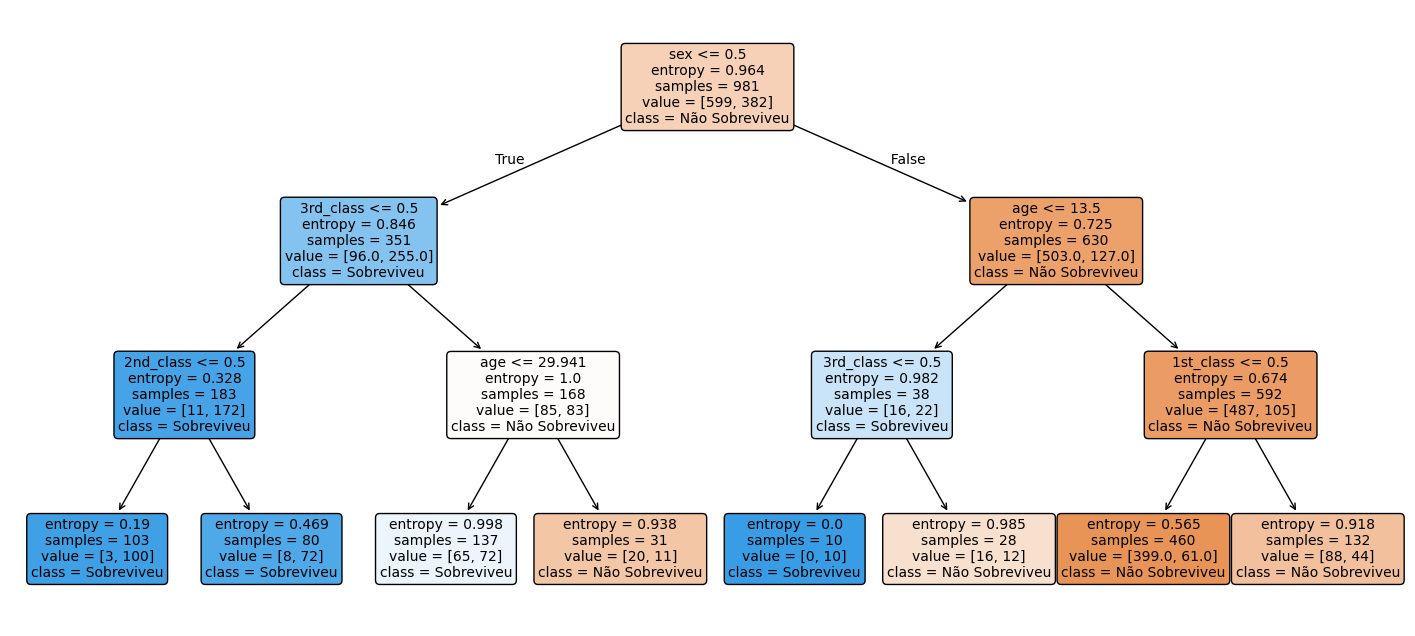

In [10]:
import matplotlib.pyplot as plt

# Configura o tamanho da figura (pol.)
plt.figure(figsize=(18, 8))

# Apresenta a árvore de decisão
tree.plot_tree(clf, feature_names=['age', 'sex', '1st_class', '2nd_class', '3rd_class'], class_names=['Não Sobreviveu', 'Sobreviveu'], filled=True, rounded=True, fontsize=10)
plt.show()

A árvore de decisão que acabamos de construir representa uma série de decisões baseadas nos dados de treinamento. Para classificar um novo passageiro, o modelo responde às perguntas de cada nó da árvore, começando pelo topo.

* **O Nó Raiz** (*Root Node*): Por exemplo, a primeira pergunta no topo da árvore pode ser algo do tipo *O sexo é <= 0.5 ?* (ou seja, estamos falando de uma mulher?). Se a resposta for **sim**, seguimos para o nó filho à esquerda; se **não**, seguimos para o nó à direita.
* **O Caminho:** Continuamos respondendo às perguntas *Estava na terceira classe?*, *Tinha menos de 13 anos?*) até chegarmos ao final de um ramo.
* **As Folhas** (*Leaf Nodes*): Quando chegamos a um nó sem filhos (uma folha), a previsão final corresponde à classe alvo que possui a maioria das instâncias naquele grupo. No nosso caso, se o caminho indicar que a passageira era uma mulher da segunda classe, a resposta final provavelmente será 1 (Sobreviveu).

### 5.2 Escolha das Perguntas pelo Algoritmo

Mas como o algoritmo decide quais perguntas devem ser feitas e em qual ordem. A resposta está no **Ganho de Informação** (*Information Gain*) ou na **Entropia** (o scikit-learn também utiliza o Índice Gini, que é uma medida de desordem muito semelhante) de cada nó da árvore de decisão.

O **Ganho de Informação** mede quanta "entropia" se perde ao responder uma pergunta — ou, em outras palavras, o quanto ficamos mais "certos" sobre a classificação após dividirmos os dados. A **Entropia** é uma medida matemática da desordem de um conjunto:

* **Entropia Nula**: Significa que o conjunto está perfeitamente puro. Todas as instâncias pertencem à mesma classe (ex: todos sobreviveram).
* **Entropia Máxima**: Ocorre quando há um número exatamente igual de instâncias de cada classe (ex: metade sobreviveu e metade não sobreviveu), representando incerteza total.

A cada nó, o algoritmo analisa as instâncias disponíveis e mede a **entropia**. Ele testará várias perguntas possíveis e selecionará aquela que gerar a divisão mais **homogênea** (com a menor **entropia** resultante nos nós filhos). O processo se repete até que a árvore atinja as condições de parada definidas (como a profundidade máxima de 3 níveis que configuramos).

# 6. Interpretando a Árvore de Decisão

Como podemos observar no gráfico da árvore, no início do processo tínhamos todas as 981 ($\approx 1309 \times 0.75$) instâncias do nosso conjunto de treinamento. Dessas, 599 correspondiam à classe 0 (não sobreviventes) e 382 à classe 1 (sobreviventes). A entropia medida para esse grupo inicial era de aproximadamente $0.964$. 

Dentre as perguntas possíveis de serem feitas, a que gerou o maior **Ganho de Informação** foi: *"O passageiro era do sexo feminino?"* (lembrando que a categoria feminina foi codificada como 0). Se a resposta for **sim**, a entropia quase não muda ($0.846$), mas se a resposta for **não**, a entropia diminui drasticamente ($0.725$, pois a proporção de homens que morreram foi muito maior do que a taxa geral de mortes). Por esse motivo, essa foi a melhor pergunta inicial a ser feita pelo algoritmo.

A partir daí, o processo continua recursivamente, analisando em cada nó apenas o subconjunto de dados que atende às condições do caminho percorrido até ali.

Cada nó mostra sequencialmente as seguintes informações:
1. A pergunta condicional.
1. A **entropia de Shannon** do grupo de dados naquele ponto.
1. O número total de amostras (*samples*) consideradas.
1. A distribuição das amostras com respeito a classe alvo.

Em cada etapa, o número de instâncias é reduzido àquelas que respondem **sim** (ramo esquerdo) ou **não** (ramo direito) à questão colocada por aquele nó. O processo continua até que um determinado critério de parada seja atendido (no nosso caso, até que tenhamos um nó de quarto nível, ou o número de amostras consideradas seja inferior a cinco).  
<center>
    <img src="./img/no-arvore-decisao.png" alt="Exemplo de um nó da Árvore de Decisão">
    <p>Exemplo de um nó da Árvore de Decisão.
</center>

### 6.1. Previsão do Modelo

Para classificar um novo passageiro, iniciamos no topo da árvore (nó raiz) e respondemos às perguntas com base nos atributos daquele passageiro em questão (queremos saber se ele sobreviveu ou não ao naufrágio do Titanic). Se a resposta for **sim**, seguimos caminhando pelo ramo da esquerda; se for **não**, seguimos caminhando pelo ramo da direita. Repetimos esse processo até atingir uma **folha** (nó mais inferior da árvore), onde a previsão final será a classe dominante daquele grupo.

**Exemplo**:
Imagine que queremos prever se uma **menina de 10 anos, viajando na primeira classe**, teria sobrevivido.
Caminhamento pela árvore:
1. **É do sexo feminino?** Sim $\rightarrow$ seguimos para o ramo da esquerda.
2. **É da terceira classe?** Não $\rightarrow$ seguimos para o ramo da direita.
3. **É da primeira classe?** Sim $\rightarrow$ seguimos para o nó correspondente.

Chegamos a uma **folha**. No conjunto de treinamento, tínhamos 137 pessoas com esse exato perfil, sendo 65 não sobreviventes e 72 sobreviventes. Portanto, a previsão do modelo para ela é: **Sobreviveu**.

De um modo geral, o modelo encontrou padrões bastante coerentes com a história: o grupo com mais vítimas fatais (449 de 496) foi o de homens adultos da 2ª e 3ª classes, enquanto a maioria das meninas da 1ª classe sobreviveu.  

<div align="center">
    <img src="./img/rose-e-jack-em-cena-de-titanic.jpg" alt="Cena do filme 'Titanic' com as personagens 'Jack' e 'Rose'" width="50%">
    <p><i>Cena icônica do filme Titanic ilustrando a diferença nas chances de sobrevivência dos passageiros.</i></p>
</div>

### 6.2. Avaliando o Desempenho no Conjunto de Treinamento

Para medir o quão bem que o modelo (árvore de decisão) se ajustou aos dados, podemos criar uma função auxiliar para exibir as métricas de avaliação.

In [11]:
from sklearn import metrics

def measure_performance(X, y, clf, show_accuracy=True, show_classification_report=True, show_confusion_matrix=True):
    # Realiza as predições para o conjunto fornecido
    y_pred = clf.predict(X)
    
    if show_accuracy:
        print(f"Acurácia: {metrics.accuracy_score(y, y_pred):.3f}\n")
        
    if show_classification_report:
        print("Relatório de Classificação:")
        print(metrics.classification_report(y, y_pred), "\n")
        
    if show_confusion_matrix:
        print("Matriz de Confusão:")
        print(metrics.confusion_matrix(y, y_pred), "\n")

# Medindo a acurácia apenas no conjunto de treinamento
measure_performance(X_train, y_train, clf, show_classification_report=False, show_confusion_matrix=False)

Acurácia: 0.792



Nossa árvore alcançou uma **acurácia** de $0.792~(79,2\%)$ com os dados de treinamento. No entanto, medir o desempenho no próprio conjunto de treinamento é um mau indicador, pois **Árvores de Decisão** são muito suscetíveis ao **overfitting** (decorar os dados de treino em vez de aprender a generalizar).

Para obter uma avaliação mais confiável sem usar o conjunto de teste antecipadamente, podemos aplicar a **Validação Cruzada Leave-One-Out (LOOCV)**. Nesse método, se tivermos $N$ amostras, o modelo é treinado $N$ vezes utilizando $N-1$ amostras e testado com a única amostra deixada de fora. A acurácia final é a média das predições de cada uma dessas etapas.

In [13]:
import numpy as np
from sklearn.model_selection import LeaveOneOut
from scipy.stats import sem

def loo_cv(X_train, y_train, clf):
    # Instancia a validação cruzada Leave-One-Out
    loo = LeaveOneOut()
    scores = np.zeros(X_train.shape[0])
    
    # Itera sobre cada divisão do conjunto de treinamento
    for train_index, test_index in loo.split(X_train):
        X_train_cv, X_test_cv = X_train[train_index], X_train[test_index]
        y_train_cv, y_test_cv = y_train[train_index], y_train[test_index]
        
        # Treina e avalia na amostra isolada
        clf_fitted = clf.fit(X_train_cv, y_train_cv)
        y_pred = clf_fitted.predict(X_test_cv)
        
        scores[test_index] = metrics.accuracy_score(y_test_cv.astype(int), y_pred.astype(int))
        
    print(f"Acurácia Média (LOO-CV): {np.mean(scores):.3f} (+/-{sem(scores):.3f})")

# Executando a validação cruzada LOOCV
loo_cv(X_train, y_train, clf)

Acurácia Média (LOO-CV): 0.781 (+/-0.013)


A **acurácia média** obtida com a validação cruzada foi de $0.781~(78,1\%)$.

A grande vantagem da validação *Leave-One-Out* é utilizar praticamente quase todos os dados disponíveis para treino em cada iteração, sendo ideal quando a base de dados é reduzida. Por outro lado, seu custo computacional é elevado, pois exige treinar um modelo novo para cada amostra.

Uma questão importante permanece: **como escolhemos os melhores hiperparâmetros** (como **profundidade máxima** e **número mínimo de amostras nas folhas**) para o modelo?

Esse processo de escolha e ajuste é conhecido como **Seleção de Modelos** (*Model Selection*).

# 7. Fontes  

1. Drew Levy - Vanderbilt Department of Biostatistics; 14/07/26; disponível em https://hbiostat.org/data/; acesso em 25/10/26.
1. "RMS Titanic"; Imagem original de F.G.O. Stuart; enviado por Mark Cartwright, publicada em 17/05/21; disponível em https://www.worldhistory.org/image/14047/rms-titanic/; acesso em 20/10/26.
1. Ana Rojo-Echeburúa; "What Is One Hot Encoding and How to Implement It in Python"; 26/06/24; disponível em https://www.datacamp.com/tutorial/one-hot-encoding-python-tutorial; acesso em 25/10/26.
1. Patrick Loeber; "Decision Tree in Python, Part 2/2 - Machine Learning From Scratch 09 - Python Tutorial"; 22/11/19; vídeo dur. 30':43"; disponível em https://www.youtube.com/watch?v=Bqi7EFFvNOg; acesso em 25/10/26.
1. Patrick Loeber; "Decision Tree in Python, Part 1/2 - Machine Learning From Scratch 08 - Python Tutorial"; 22/11/19; vídeo dur. 10':34"; disponível em https://www.youtube.com/watch?v=jVh5NA9ERDA; acesso em 25/10/26.

# Anexo-A: Fundamentos de Àrvore de Decisão (AD)

### A.1 Cálculo da Entropia
Vamos usar um exemplo prático para explicar os conceitos e a matemática por trás da árvore de decisão.  
Suponha que temos 10 amostras/observações sobre a mobilidade urbana de uma determinada pessoa para ir ao trabalho: caminhando ou de ônibus. As amostras tem duas classes (características, *features*): "chuva" para dias com chuva e "minutos" para o tempo gasto no trajeto; além da predição (classe com rótulos: "sim" ou "não").  

Uma **árvore de decisão** é um algoritmo que pode responder à pergunta: **Essa pessoa vai caminhando hoje?**  
A **árvore de decisão** divide os dados de modo que se tenha a melhor separação das classes, e é também a base para o popular modelo **Floresta Randômica**.

Exemplo:  
<span style="font-family:consolas">
["chuva", "minutos", "caminhando"]  
[ 1, 30, <span style="color:rgb(9, 128, 218)">'Não'</span>],  
[ 1, 15, <span style="color:rgb(9, 128, 218)">'Não'</span>],  
[ 1, 05, <span style="color:rgb(9, 128, 218)">'Não'</span>],  
[ 0, 10, <span style="color:rgb(9, 128, 218)">'Não'</span>],  
[ 0, 05, <span style="color:rgb(9, 128, 218)">'Não'</span>],  
[ 0, 15, <span style="color:rgb(183, 5, 5)">'Sim'</span>],  
[ 0, 20, <span style="color:rgb(183, 5, 5)">'Sim'</span>],  
[ 0, 25, <span style="color:rgb(183, 5, 5)">'Sim'</span>],  
[ 0, 30, <span style="color:rgb(183, 5, 5)">'Sim'</span>],  
[ 0, 30, <span style="color:rgb(183, 5, 5)">'Sim'</span>]  
</span>

In [1]:
classes = ["chuva", "minutos", "caminhando"]
caminhada = [
    [ 1, 30, 'Não'],
    [ 1, 15, 'Não'],
    [ 1,  5, 'Não'],
    [ 0, 10, 'Não'],
    [ 0,  5, 'Não'],
    [ 0, 15, 'Sim'],
    [ 0, 20, 'Sim'],
    [ 0, 25, 'Sim'],
    [ 0, 30, 'Sim'],
    [ 0, 30, 'Sim']
]

Na raiz da **Árvore de Decisão** colocamos todas as amostras/observações, e então fazemos a primeira questão: **Está chovendo?** Se a resposta for `chuva = 1`, então continuamos o caminhamento para o nó à direita da AD, no qual colocamos somente as amostras com `chuva = 1` (nesse exemplo, as três primeiras amostras do conjunto de dados). Por outro lado, se a resposta for `chuva = 0`, então continuamos o caminhamento para o nó à esquerda da AD, no qual colocamos somente as amostras concordantes com `chuva = 0` (nesse exemplo, as demais amostras).  

A pergunta seguinte avalia se o tempo gasto no trajeto é maior que 10 minutos. Se a resposta for **verdade**, então continuamos o caminhamento para o nó da direita, no qual colocamos todas as amostras com tempos de trajeto maiores que 10 minutos, e colocamos no nó à esquerda as demais amostras. E dessa forma podemos predizer para uma nova amostra se a pessoa vai caminhando ou de ônibus para o trabalho.

<div align="center">
    <img src="./img/caminhando_ou_nao.png" alt="Desenho de uma árvore de decisão (binária) de profundidade três, para o exemplo da mobilidade urbana" width="35%">
    <p>Árvore de Decisão de profundidade três, para o exemplo da mobilidade urbana.</p>
</div>

A divisão da AD pode se dar pela quantidade de níveis/profundidade ou pela quantidade mínima de amostras em cada nó folha, para se evitar o *overfitting* do algoritmo.  
Mas por que a AD do exemplo começou com a pergunta sobre "chuva"? E por que testamos o tempo gasto com 10 e não com 5, ou 15 minutos? Esses valores podem ser determinados pelo algoritmo de melhor divisão baseada na **entropia** (medida da incerteza) dos dados de treino, ou seja, no **Ganho de Informação** em cada nó da AD.

$$E = - \sum_{i=0}^{N-1} p(X_i).log_2 \left ( p(X_i) \right)$$
onde: $p(X_i) = \frac{\# x_i}{N}$

Exemplo: Admitindo classe alvo ("caminhando") com valores 'Não' = 0 e 'Sim' = 1, temos:  
$$S = [0,0,0,0,0,1,1,1,1,1]$$
$$E = - \frac{5}{10}.log_2 \left ( \frac{5}{10} \right ) - \frac{5}{10}.log_2 \left ( \frac{5}{10} \right ) = -0.5~log_2 (-0.5) -0.5~log_2 (-0.5) = 1$$

Portanto, para o primeiro nó temos $E=1$, incerteza máxima, quantidade iguais de amostras para ambas mobilidade urbano: "caminhando" ou "ônibus".

### Ganho de Informação - GI
$$GI = E(pai) - média\_ponderada[E(filhos)]$$
Exemplo:  

$$S = [0,0,0,0,0,1,1,1,1,1], ~~~~~ S1 = [0,0,1,1,1,1,1], ~~~~~ S2 = [0,0,0]$$


$$GI = E(S) - [(7/10)\times E(S1) + (3/10)\times E(S2)]$$
$$GI = 1 - [0.7 \times 0.863 + 0.3 \times 0] = 0.395$$


### A.2 Algoritmo para Treinamento do Modelo (Construção da AD)
- Inicie no nó do topo e em cada nó selecione a melhor divisão baseada no melhor Ganho de Informação.
- Busca gulosa (*greedy search*): percorra todas as características e por todos os limiares (todos os possíveis valores de cada característica).
- Guarde a melhor característica de divisão e o limiar da divisão de cada nó.
- Construa a árvore recursivamente.
- Aplique algum critério de parada para interromper o crescimento da árvore, por exemplo: profundidade máxima, quantidade mínima de amostras no nó, escassez de classes para distribuição no nó.
- Quando tivermos um nó folha, armazene o rótulo da classe mais comum deste nó. 

### A.3 Algoritmo para Teste/Predição de uma Amostra Nova (Percorrendo a AD)
- Percorra a AD recursivamente
- Em cada nó olhe na característica de melhor divisão do vetor de característica de teste 'x' e vá para esquerda ou direita, dependendo de $x[indice\_característica] <= limiar$.
- Quando alcançar um nó folha, retorne o rótulo da classe mais comum armazenado no nó.

### A.4 Implementação da AD

In [15]:
from collections import Counter
import numpy as np

def entropy(y):
    ''' Calcula a entropia do vetor da característica alvo 'y' '''
    hist = np.bincount(y)       # Conta o número de ocorrências de cada valor no vetor de inteiros não negativos.
    ps = hist / len(y)
    return -np.sum([p * np.log2(p) for p in ps if p > 0])


class Node:
    # o asterisco antes de 'value' significa que para passar o valor do argumento 'value' é preciso passá-lo explicitamente como 'value="valor"'
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf_node(self):
        return self.value is not None


class DecisionTree:
    def __init__(self, min_samples_split=2, max_depth=100, n_feats=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.n_feats = n_feats
        self.root = None

    def fit(self, X, y):
        # constroi a árvore
        self.n_feats = X.shape[1] if not self.n_feats else min(self.n_feats, X.shape[1])
        self.root = self._grow_tree(X, y)

    def predict(self, X):
        # percorre a árvore
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        n_labels = len(np.unique(y))

        # stopping criteria
        if (depth >= self.max_depth  or  n_labels == 1  or  n_samples < self.min_samples_split):
            leaf_value = self._most_common_label(y)
            return Node(value=leaf_value)

        feat_idxs = np.random.choice(n_features, self.n_feats, replace=False)

        # greedily select the best split according to information gain
        best_feat, best_thresh = self._best_criteria(X, y, feat_idxs)

        # grow the children that result from the split
        left_idxs, right_idxs = self._split(X[:, best_feat], best_thresh)
        left = self._grow_tree(X[left_idxs, :], y[left_idxs], depth + 1)
        right = self._grow_tree(X[right_idxs, :], y[right_idxs], depth + 1)
        return Node(best_feat, best_thresh, left, right)

    def _best_criteria(self, X, y, feat_idxs):
        best_gain = -1
        split_idx, split_thresh = None, None
        for feat_idx in feat_idxs:
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)
            for threshold in thresholds:
                gain = self._information_gain(y, X_column, threshold)
                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = threshold
        return split_idx, split_thresh

    def _information_gain(self, y, X_column, split_thresh):
        # parent loss
        parent_entropy = entropy(y)

        # generate split
        left_idxs, right_idxs = self._split(X_column, split_thresh)
        if len(left_idxs) == 0 or len(right_idxs) == 0:
            return 0

        # compute the weighted avg. of the loss for the children
        n = len(y)
        n_l, n_r = len(left_idxs), len(right_idxs)
        e_l, e_r = entropy(y[left_idxs]), entropy(y[right_idxs])
        child_entropy = (n_l / n) * e_l + (n_r / n) * e_r

        # information gain is difference in loss before vs. after split
        ig = parent_entropy - child_entropy
        return ig

    def _split(self, X_column, split_thresh):
        left_idxs = np.argwhere(X_column <= split_thresh).flatten()
        right_idxs = np.argwhere(X_column > split_thresh).flatten()
        return left_idxs, right_idxs

    def _traverse_tree(self, x, node):
        if node.is_leaf_node():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)

    def _most_common_label(self, y):
        counter = Counter(y)
        most_common = counter.most_common(1)[0][0]
        return most_common


if __name__ == "__main__":
    # Imports
    from sklearn import datasets
    from sklearn.model_selection import train_test_split

    def accuracy(y_true, y_pred):
        accuracy = np.sum(y_true == y_pred) / len(y_true)
        return accuracy

    data = datasets.load_breast_cancer()
    X, y = data.data, data.target
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1234)

    clf = DecisionTree(max_depth=10)
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)
    acc = accuracy(y_test, y_pred)

    print("Acurácia:", acc)

Acurácia: 0.9298245614035088
